### **მანქანური სწავლება**

In [93]:
import warnings
warnings.filterwarnings("ignore")

In [94]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

### Supervised vs. Unsupervised Learning

<img src="../../images/supervised_learning.png" alt="supervised vs unsupervised" width=800>

<img src="../../images/unsupervised_learning.png" alt="unsupervised" width=800>

სწავლების მეთოდების შედარება:

<img src="../../images/sup_vs_unsup.png" alt="supervised vs unsupervised" width=800>

ალგორითმები:

 - Supervised Learning
   - Regression
     - Linear Regression
     - Decision Trees
     - Random Forest
     - XGBoost
     - K-Nearest Neighbors
     - Support Vector Machines
     - Neural Networks
   - Classification
     - Logistic Regression
     - Decision Trees
     - Random Forest
     - XGBoost
     - K-Nearest Neighbors
     - Support Vector Machines
     - Neural Networks
 - Unsupervised Learning
   - Clustering
     - K-Means Clustering
     - DBSCAN (Density-Based Spatial Clustering)
     - OPTICS (Ordering Points To Identify the Clustering Structure)
     - Hierarchical Clustering
     - PCA (Principal Component Analysis)

განსხვავება კლასიფიკაციასა და რეგრესიას შორის:

<img src="../../images/class_reg.png" alt="classification vs regression" width=800>

სწავლების მეთოდების გამოყენების მაგალითები:

<img src="../../images/ml_examples.png" alt="supervised vs unsupervised" width=800>

პოპულარული მანქანური სწავლების ალგორითმები:
 - Supervised Learning: 
   - Linear Regression
   - Logistic Regression
   - Decision Trees
   - Random Forests
   - XGBoost
   - Support Vector Machines (SVM)
 - Unsupervised Learning:
   - K-Means Clustering
   - DBSCAN

### Scikit-learn

[Scikit-learn](https://scikit-learn.org/stable/) განკუთვნილია მანქანური სწავლებისთვის. იგი უზრუნველყოფს მძლავრ, მარტივად გამოსაყენებელ და ეფექტურ ალგორითმებს მონაცემთა დამუშავებისთვის, მოდელირებისათვის და შეფასებისთვის.
 - მონაცემთა წინასწარი დამუშავება (Preprocessing)
 - Supervised Learning
 - Unsupervised Learning
 - მოდელების შეფასება (Model Evaluation)
 - მოდელების შერჩევა და ჯვარედინი ვერიფიკაცია (Model Selection & Cross-Validation)
 - ჰიპერპარამეტრების ოპტიმიზაცია (Hyperparameter Tuning)

### Medical Cost Personal Datasets

In [95]:
# მონაცემების წაკითხვა csv ფაილიდან
df_insurance = pd.read_csv("../../datasets/medical_cost/insurance.csv")
df_insurance.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [46]:
df_insurance.describe(exclude=np.number)

,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


In [47]:
print(df_insurance.region.unique())

['southwest' 'southeast' 'northwest' 'northeast']


| Column Type                         | Example Columns                 | Example Unique Values                                  | Recommended Encoder                      | Notes                                                                                                                    |
| ----------------------------------- | ------------------------------- | ------------------------------------------------------ | ---------------------------------------- | ------------------------------------------------------------------------------------------------------------------------ |
| **Binary categorical**              | `sex`, `smoker`                 | `["male", "female"]`, `["yes", "no"]`                  | **Label Encoding** or **Manual Mapping** | გამოიყენება როდესაც სვეტი ზუსტად ორ კატეგორიას შეიცავს<br><br> OneHotEncoder არაა საჭირო |
| **Nominal (unordered) categorical** | `region`                        | `["southwest", "southeast", "northwest", "northeast"]` | **One-Hot Encoding**                     | ორზე მეტი კატეგორიისათვის<br><br>არ ქმნის ცრუ რიგითობას კატეგორიებს შორის<br> 
| **Ordinal (ordered) categorical**   | `education_level`, `risk_level` | `["low", "medium", "high"]`                            | **Ordinal Encoding**                     | გამოიყენება, როცა კატეგორიებს ბუნებრივი მიმდევრობა აქვთ                     |

### Regression 
#### დაზღვევის ხარჯების (charges) პროგნოზირება

In [98]:
# Preprocessing: 

# გარდავქმნათ str სვეტები რიცხვოვან მონაცემებთან categorical -> numerical
encoder = LabelEncoder()
df_insurance["sex_encoded"] = encoder.fit_transform(df_insurance["sex"])
df_insurance["smoker_encoded"] = encoder.fit_transform(df_insurance["smoker"])

encoder = OneHotEncoder(sparse_output=False)
region_encoded = encoder.fit_transform(df_insurance[["region"]])

df_region = pd.DataFrame(region_encoded, columns=encoder.get_feature_names_out(["region"]))
df_insurance = pd.concat([df_insurance, df_region], axis=1)

In [52]:
# გამოვყოთ მახასიათებლები (features - X) და სამიზნე სვეტი (target variable - y), რომლის პროგნოზირებაც უნდა მოხდეს 
X = df_insurance[["age", "bmi", "children", "sex_encoded", "smoker_encoded", 
                  "region_northeast", "region_northwest", "region_southeast", "region_southwest"]]
y = df_insurance["charges"]

# Train-Test Split 
# მონაცემები დავყოთ, training sets - მონაცემების ის ნაწილი რომელიც მოდელს გადაეცემა შესასწავლად და testing sets - სატესტო მონაცემები 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # (80% training, 20% testing)

In [53]:
# ავარჩიოთ წრფივი რეგრესია მოდელად 
model = LinearRegression()
model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [54]:
# Training - მოდელის გაწვრთნა: მოდელს გადავცემთ მახასიათებლებს და სამიზნე მონაცემებს (X_train, y_train)
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [55]:
# Testing - X_test მახასიათებლებზე მოდელის პროგნოზი
y_pred = model.predict(X_test)
print("Prediction:", y_pred[:4])
print("Actual:    ", y_test.values[:4])

Prediction: [ 8969.55027444  7068.74744287 36858.41091155  9454.67850053]
Actual:     [ 9095.06825  5272.1758  29330.98315  9301.89355]


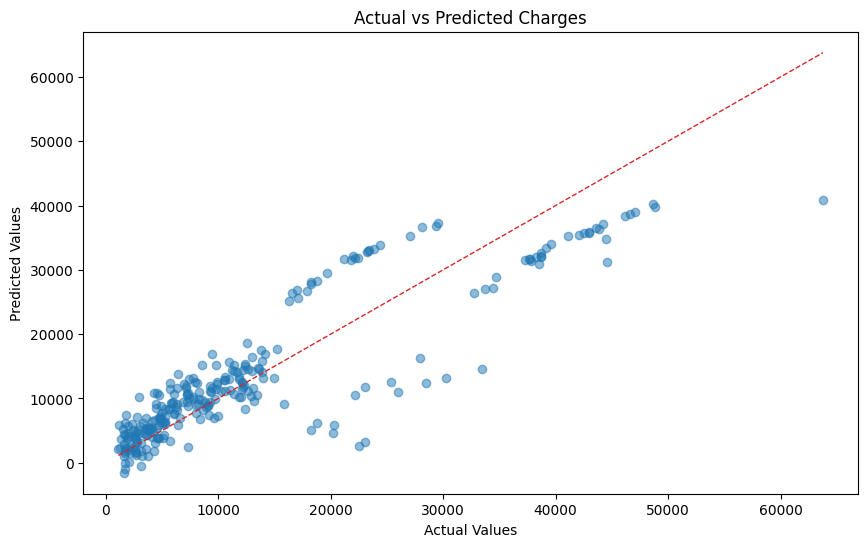

In [56]:
# პროგნოზისა და ნამდვილი მონაცემების შედარება
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(y_test, y_pred, alpha=0.5)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--", lw=1, color="C3")
ax.set_title("Actual vs Predicted Charges")
ax.set_xlabel("Actual Values")
ax.set_ylabel("Predicted Values");

### Classification

#### Penguins Dataset

<img src="../../images/penguin.png" alt="penguin" width="700">

In [104]:
# Penguins Dataset
df_penguin = sns.load_dataset("penguins")
df_penguin = df_penguin.dropna().reset_index(drop=True)
df_penguin.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


In [105]:
df_penguin.island.unique()

array(['Torgersen', 'Biscoe', 'Dream'], dtype=object)

In [106]:
# Preprocessing: 

# გარდავქმნათ str სვეტები რიცხვოვან მონაცემებთან categorical -> numerical
encoder = LabelEncoder()
df_penguin["sex_encoded"] = encoder.fit_transform(df_penguin["sex"])

encoder = OneHotEncoder(sparse_output=False)
category_encoded = encoder.fit_transform(df_penguin[["island"]])

df_category = pd.DataFrame(category_encoded, columns=encoder.get_feature_names_out(["island"]))
df_penguin = pd.concat([df_penguin, df_category], axis=1)

In [107]:
# გამოვყოთ მახასიათებლები (features - X) და სამიზნე სვეტი (target variable - y), რომლის პროგნოზირებაც უნდა მოხდეს 
X = df_penguin[["bill_length_mm", "bill_depth_mm", "flipper_length_mm",
                "body_mass_g", "sex_encoded", "island_Biscoe", "island_Dream", "island_Torgersen"]]
y = df_penguin["species"]

In [108]:
# მონაცემები დავყოთ, training sets - მონაცემების ის ნაწილი რომელიც გადაეცემა შესასწავლად და testing sets - სატესტო მონაცემები 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # (80% training, 20% testing)

In [109]:
model = DecisionTreeClassifier(random_state=8)
model

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,8
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [110]:
# Training - მოდელის გაწვრთნა: მოდელს გადავცემთ მახასიათებლებს და სამიზნე მონაცემებს (X_train, y_train)
model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,8
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [111]:
# Testing - X_test მახასიათებლებზე მოდელის პროგნოზი
y_pred = model.predict(X_test)
print("Prediction:", y_pred[:7])
print("Actual:    ", y_test.values[:7])

Prediction: ['Adelie' 'Gentoo' 'Adelie' 'Chinstrap' 'Adelie' 'Gentoo' 'Gentoo']
Actual:     ['Adelie' 'Gentoo' 'Adelie' 'Chinstrap' 'Adelie' 'Gentoo' 'Gentoo']


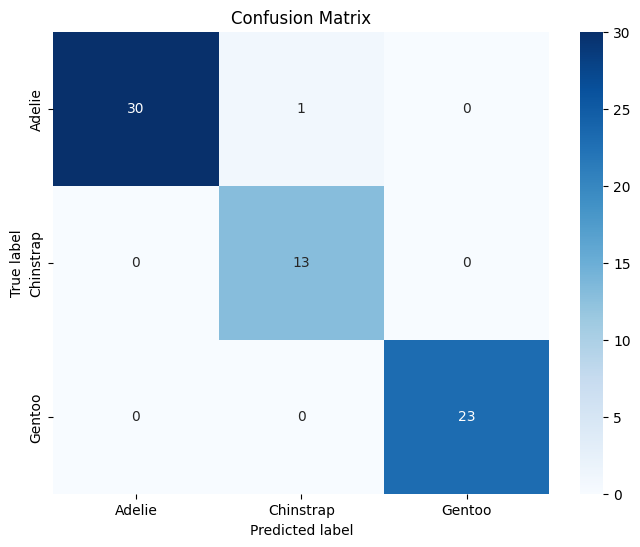

In [112]:
cm = confusion_matrix(y_test, y_pred)

# Plotting the confusion matrix - რამდენი მონაცემის სწორ კლასში კლასიფიკაცია მოხდა და რამდენი მისკლასიფიცირებული მონაცემი გვაქვს
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Adelie", "Chinstrap", "Gentoo"], yticklabels=["Adelie", "Chinstrap", "Gentoo"])
plt.title("Confusion Matrix")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.show()

In [113]:
X_test[y_test != y_pred]

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex_encoded,island_Biscoe,island_Dream,island_Torgersen
75,42.9,17.6,196.0,4700.0,1,0.0,0.0,1.0


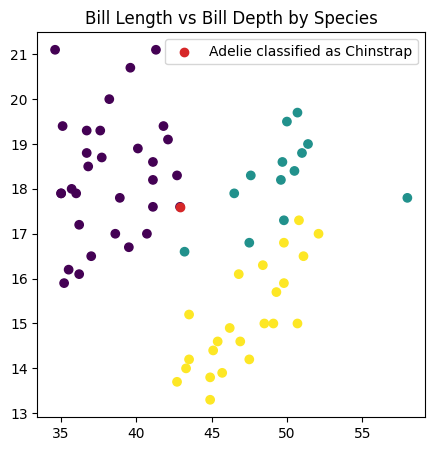

In [114]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_test["bill_length_mm"], X_test["bill_depth_mm"], c=y_test.astype("category").cat.codes)
ax.scatter(X_test[y_test != y_pred]["bill_length_mm"], X_test[y_test != y_pred]["bill_depth_mm"], color="C3", label="Adelie classified as Chinstrap")
ax.set_title("Bill Length vs Bill Depth by Species")
ax.legend()
plt.show()

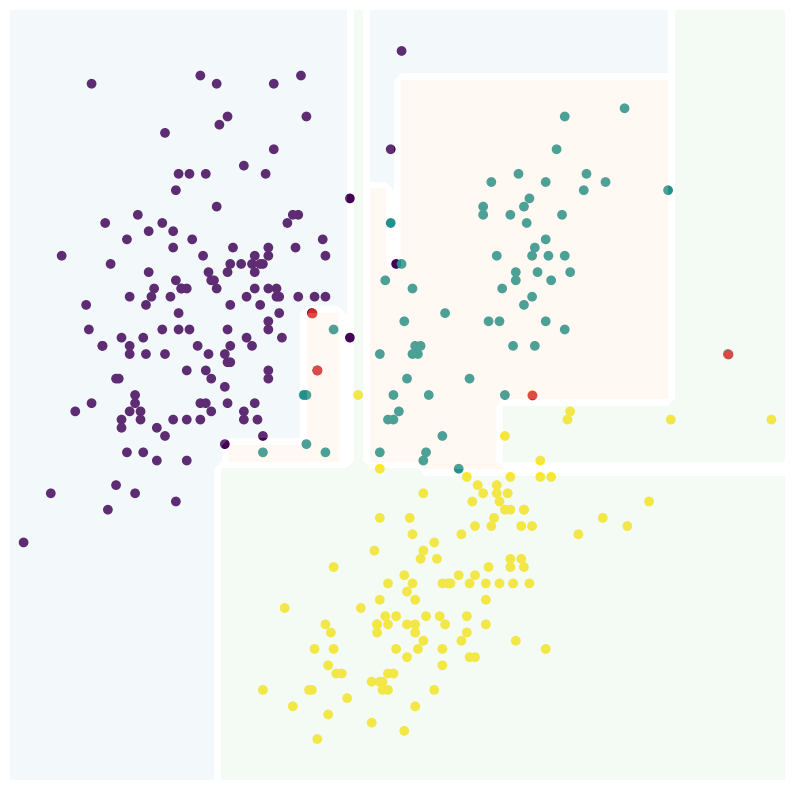

In [119]:
cm = plt.cm.RdBu
clf = DecisionTreeClassifier(random_state=8)
clf = make_pipeline(StandardScaler(), clf)
clf.fit(X_train[["bill_length_mm", "bill_depth_mm"]], y_train)
y_pred = clf.predict(X[["bill_length_mm", "bill_depth_mm"]])
score = clf.score(X[["bill_length_mm", "bill_depth_mm"]], y)

fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(X["bill_length_mm"], X["bill_depth_mm"], c=y.astype("category").cat.codes)
ax.scatter(X[y != y_pred]["bill_length_mm"], X[y != y_pred]["bill_depth_mm"], color="C3", label="Adelie classified as Chinstrap")
DecisionBoundaryDisplay.from_estimator(clf, X[["bill_length_mm", "bill_depth_mm"]], cmap=cm, alpha=0.2, ax=ax, eps=0.5)
plt.axis("off")
plt.show()

### Clustering

In [120]:
# რიცხვითი მახასიათებლების შერჩევა კლასტერინგისთვის
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X = X[features]

# მახასიათებლების ტრანსფორმაცია
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [121]:
# KMeans Clustering 3 არის კლასტერების რაოდენობა, რადგანაც პინგვინების 3 კგუფი გვაქვს
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_scaled)

,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [127]:
# Cluster-Labels ანუ თუ რომელ კგუფს მიეკუთვნა რომელი მონაცემი, ამ ინფორმაციას ვამატებთ ცხრილში

cluster_mapping = {0: "Adelie", 1: "Gentoo", 2: "Chinstrap"}
df_penguin["cluster"] = [cluster_mapping[label] for label in kmeans.labels_]

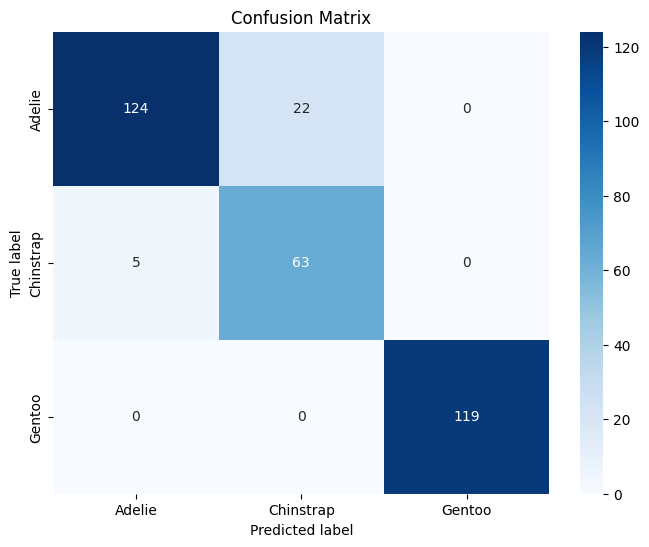

In [91]:
cm = confusion_matrix(df_penguin["species"], df_penguin["cluster"])

# Plotting the confusion matrix - რამდენი მონაცემის სწორ ჯგუფში კლასტერინგი მოხდა და რამდენი არასწორად დაჯგუფებული მონაცემი გვაქვს
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Adelie", "Chinstrap", "Gentoo"], yticklabels=["Adelie", "Chinstrap", "Gentoo"])
plt.title("Confusion Matrix")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.show()

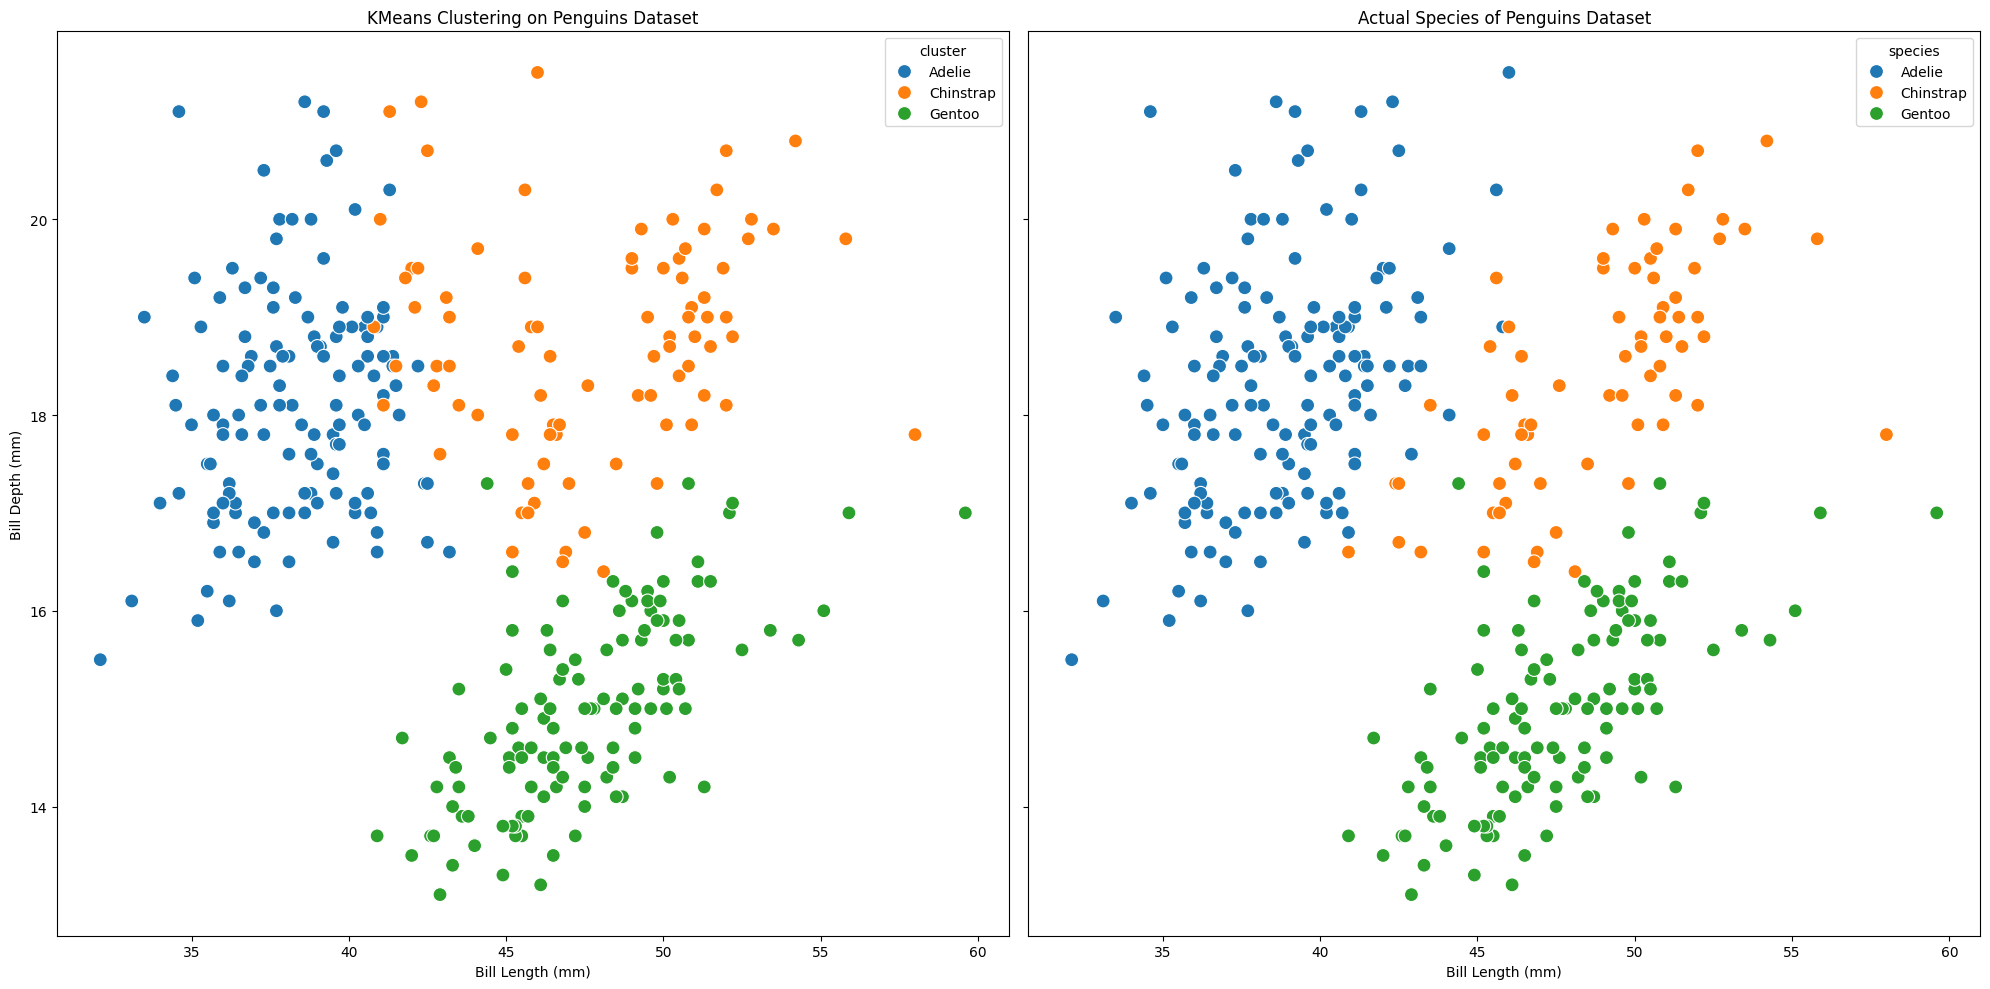

In [129]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10), sharex=True, sharey=True)

# KMeans Clustering
sns.scatterplot(data=df_penguin, x="bill_length_mm", y="bill_depth_mm", hue="cluster", legend="full", ax=ax1, s=100)
ax1.set_title("KMeans Clustering on Penguins Dataset")
ax1.set_xlabel("Bill Length (mm)")
ax1.set_ylabel("Bill Depth (mm)")

# Actual Species
sns.scatterplot(data=df_penguin, x="bill_length_mm", y="bill_depth_mm", hue="species", legend="full", ax=ax2, s=100)
ax2.set_title("Actual Species of Penguins Dataset")
ax2.set_xlabel("Bill Length (mm)")
ax2.set_ylabel("Bill Depth (mm)")

plt.tight_layout()
plt.show()

### Overfitting vs. Underfitting

- Overfitting (გადაჭარბებული მორგება): მოდელი სწავლობს არა მხოლოდ ზოგად კანონზომიერებებს, არამედ სატრენინგო მონაცემების "ხმაურსაც". შედეგად, ის კარგად მუშაობს სატრენინგო მონაცემებზე, მაგრამ ცუდად ახალ მონაცემებზე.

- Underfitting (არასაკმარისი მორგება): მოდელი ზედმეტად მარტივია და ვერ იჭერს მონაცემების მნიშვნელოვან კანონზომიერებებს, რის გამოც ცუდად მუშაობს როგორც სატრენინგო, ისე სატესტო მონაცემებზე.

<img src="../../images/model_performance.jpg" width="700"> 

### Bias-Variance Tradeoff

| Bias vs. Variance | Training vs. validation error |
|------|---------|
| <img src="../../images/tradeoff.png" width="550"> | <img src="../../images/bias_variance.png" width="500"> |

მიკერძოება (Bias) და ცვალებადობა (Variance) მანქანურ სწავლებაში:

- Bias (მიკერძოება) არის მოდელის სიმარტივით გამოწვეული შეცდომა.

    - High Bias (Underfitting): მოდელი ზედმეტად მარტივია და ვერ იჭერს მონაცემების მნიშვნელოვან კანონზომიერებებს, რის შედეგადაც იგი ცუდად მუშაობს როგორც სატრენინგო, ისე სატესტო მონაცემებზე.
    - Low Bias: მოდელი უკეთ იჭერს მონაცემების კანონზომიერებებს, თუმცა შესაძლოა, ჯერ კიდევ მაღალი Variance ჰქონდეს.
      
- Variance (ცვალებადობა) – მოდელის მგრძნობელობა სატრენინგო მონაცემების მიმართ.

    - High Variance (Overfitting): მოდელი ზედმეტად რთულია და მონაცემების "ხმაურსაც" იჭერს, რის გამოც სატრენინგო მონაცემებზე კარგად მუშაობს, მაგრამ ახალ მონაცემებზე სუსტი შედეგი აქვს.
    - Low Variance: მოდელი კარგად გენერალიზდება ახალ მონაცემებზე, თუმცა შესაძლოა, ჯერ კიდევ მაღალი Bias ჰქონდეს.
      
Bias-Variance Tradeoff გულისხმობს ამ ორ ფაქტორს შორის ოპტიმალური ბალანსის პოვნას, რათა მოდელმა შეძლოს ახალი მონაცემების სწორად პროგნოზირება. 

ანუ როდესაც მოდელი ძალიან მარტივი და ნაკლებად კომპლექსურია, ექნება მაღალი bias და დაბალი Variance. იმისათვის რომ გვქონდეს დაბალი bias, მოდელი უნდა გავხადოთ უფრო კომპლექსური, რაც მოგვცემს მაღალ variance.